# Random numbers and simulation

**Lecture 8 · Wednesday, 4 November 2026 · Notebook 1 of 1**

Economies are hit by shocks: good and bad harvests, booms and recessions, lucky and unlucky years for a country's growth. To study such an economy on a computer, we need **random numbers** we can reproduce, **averages over many draws** (Monte Carlo), and **simulations over time**.

The running macro question in Video 8C: **is a recession permanent, or does the economy return to its trend?**

## How to work

| Recording | Sections |
| --- | --- |
| Video 8A: Random draws, seeds and distributions | 1–2 |
| Video 8B: Monte Carlo: dice and doubling incomes | 3 |
| Video 8C: Is a recession permanent? Simulating over time | 4–5 |

**Before class (Tuesday, 23:59):** after the videos, solve warm-ups **W1–W2** in `Exercises.ipynb`, enter your answers in the Absalon quiz and upload the notebook with your code. Class (Wednesday 4 November, together with Lecture 7) starts with the most common mistakes.

**Reuse from Lectures 1–7:** loops, functions, a small class, arrays, Boolean masks, `np.sum(..., axis=...)`, histograms and a known answer as a test. The normal distribution and the law of large numbers are also in your statistics course this semester. **New:** random number generators, Monte Carlo and simulating many economies at once.

**Table of contents**<a id='toc0_'></a>
- 1. [Random draws and seeds](#toc1_)
- 2. [Distributions](#toc2_)
- 3. [Monte Carlo: averages over many draws](#toc3_)
- 4. [Is a recession permanent? Simulating over time](#toc4_)
- 5. [Summary](#toc5_)
- 6. [Optional: saving simulation results](#toc6_)

<a id='video-8a'></a>
> **Start Video 8A**  
> Question: how can a computer produce "random" numbers that we can reproduce tomorrow?

## 1. <a id='toc1_'></a>[Random draws and seeds](#toc0_)

A computer produces **pseudo-random numbers**: a fixed algorithm generates numbers that look random. The algorithm starts from a **seed**. The same seed gives the same sequence, so a simulation can be rerun and checked. The choice of seed itself is arbitrary.

`np.random.default_rng(seed)` creates a **generator**. We then draw from it, e.g. `rng.random(5)` for five uniform numbers between 0 and 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
rng = np.random.default_rng(2026)
print('First five draws: ', rng.random(5))
print('Next five draws:  ', rng.random(5))

rng_again = np.random.default_rng(2026)
print('Same seed, again: ', rng_again.random(5))

First five draws:  [0.17893481 0.63991317 0.4672684  0.37050053 0.35491733]
Next five draws:   [0.79051825 0.90514384 0.17735319 0.6527848  0.29830277]
Same seed, again:  [0.17893481 0.63991317 0.4672684  0.37050053 0.35491733]


Two rules to remember:

1. **Drawing again continues the sequence**: the second line differs from the first.
2. **A new generator with the same seed starts over**: the third line repeats the first.

**Pause and predict:** what happens if we create the generator with seed 7 instead?

In [3]:
rng_other = np.random.default_rng(7)
print('Seed 7:           ', rng_other.random(5))

Seed 7:            [0.62509547 0.8972138  0.77568569 0.22520719 0.30016628]


### Why a local generator?

Older code uses one **global** seed, `np.random.seed(...)`, shared by the whole session. Then any unrelated draw elsewhere changes your numbers, even with the same seed:

In [4]:
# a. old style: one global stream for everything
np.random.seed(2026)
first = np.random.normal(size=3)

np.random.seed(2026)
_ = np.random.random(10)            # an unrelated draw somewhere else
second = np.random.normal(size=3)
print('Global seed, same results?', np.allclose(first, second))

# b. new style: our own generator is not affected by other draws
rng_a = np.random.default_rng(2026)
first = rng_a.normal(size=3)

rng_b = np.random.default_rng(2026)
_ = np.random.random(10)            # the same unrelated draw
second = rng_b.normal(size=3)
print('Local generator, same results?', np.allclose(first, second))

Global seed, same results? False
Local generator, same results? True


**Rule for this course:** create one generator with `np.random.default_rng(seed)` and draw everything from it. Pass it into functions that need random numbers.

## 2. <a id='toc2_'></a>[Distributions](#toc0_)

A generator can draw from many distributions. Three we use:

| Call | Distribution | Example |
| --- | --- | --- |
| `rng.uniform(low, high, size)` | every value in `[low, high)` equally likely | a random share between 0 and 1 |
| `rng.normal(mean, std, size)` | bell-shaped around the mean | a growth shock |
| `rng.integers(low, high, size)` | whole numbers from `low` up to `high - 1` | a die: `rng.integers(1, 7, size)` |

`rng.beta(a, b, size)` gives shares between 0 and 1 that are more likely near one end. A histogram of many draws shows the shape of each distribution.

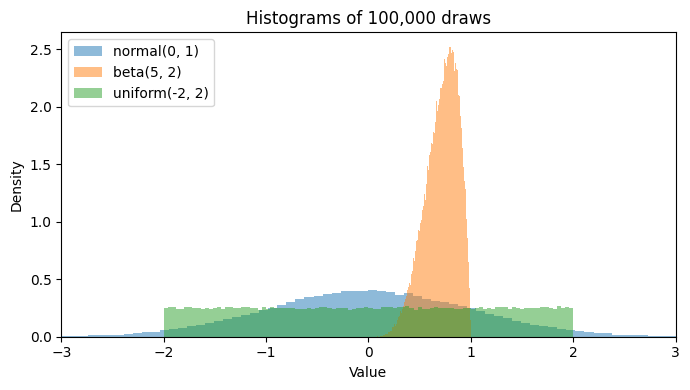

In [5]:
rng = np.random.default_rng(123)
N = 100_000

X = rng.normal(0.0, 1.0, N)
Y = rng.beta(5, 2, N)
Z = rng.uniform(-2.0, 2.0, N)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.hist(X, bins=100, density=True, alpha=0.5, label='normal(0, 1)')
ax.hist(Y, bins=100, density=True, alpha=0.5, label='beta(5, 2)')
ax.hist(Z, bins=100, density=True, alpha=0.5, label='uniform(-2, 2)')
ax.set_xlim(-3, 3)
ax.set_xlabel('Value')
ax.set_ylabel('Density')
ax.set_title('Histograms of 100,000 draws')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

### Compare the draws with a known distribution

`density=True` scales each histogram so that its area is one. We can then draw the exact **normal density** on top of it with `norm.pdf(x, mean, std)` from `scipy.stats`. If the generator works, the curve should follow the histogram.

**Pause and predict:** how well will 100,000 draws match the curve?

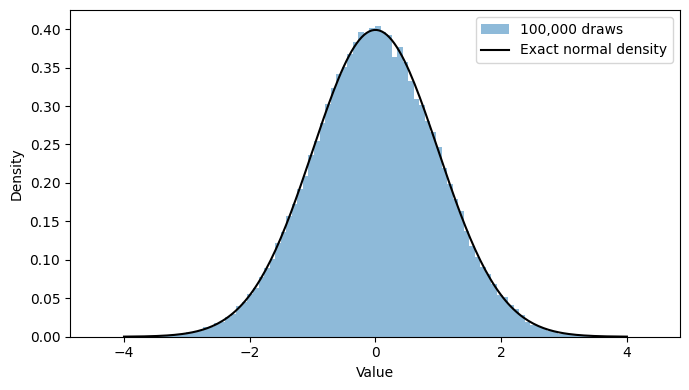

Mean of the draws: 0.0013 (exact: 0)
Std of the draws:  0.9998 (exact: 1)


In [6]:
x_grid = np.linspace(-4.0, 4.0, 200)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.hist(X, bins=100, density=True, alpha=0.5, label='100,000 draws')
ax.plot(x_grid, norm.pdf(x_grid, 0.0, 1.0), color='black', label='Exact normal density')
ax.set_xlabel('Value')
ax.set_ylabel('Density')
ax.legend()
fig.tight_layout()
plt.show()

print(f'Mean of the draws: {np.mean(X):.4f} (exact: 0)')
print(f'Std of the draws:  {np.std(X):.4f} (exact: 1)')

> **Stop Video 8A.** You can create a reproducible generator, draw from a distribution and check the draws against a known answer.

<a id='video-8b'></a>
> **Start Video 8B**  
> Question: how can random draws answer a question that has one exact answer?

## 3. <a id='toc3_'></a>[Monte Carlo: averages over many draws](#toc0_)

**Monte Carlo** means: to find an expected value or a probability, simulate the random situation many times and take the **average**. By the **law of large numbers**, the average gets close to the exact answer when the number of draws $N$ is large:

$$\frac{1}{N}\sum_{i=1}^N g(X_i)\;\approx\;\mathbb{E}[g(X)].$$

### 3.1 A dice cup

We start where the exact answer is easy: the sum of four dice has expected value $4\times3.5=14$. The class below (Lecture 3) holds a generator and rolls the dice.

In [7]:
class DiceCup:

    def __init__(self, ndice, rng):
        self.ndice = ndice
        self.rng = rng
        self.dice = None

    def roll(self):
        self.dice = self.rng.integers(1, 7, size=self.ndice)
        print(self.dice)


cup = DiceCup(4, np.random.default_rng(2026))
cup.roll()
cup.roll()

[6 2 1 4]
[3 3 1 3]


One roll tells us little. Monte Carlo rolls **many times** and averages. Here we roll four dice 10,000 times in one array: each **row** is one roll, and `np.sum(..., axis=1)` adds up each row.

**Pause and predict:** will the average be exactly 14?

In [8]:
rng = np.random.default_rng(2026)
rolls = rng.integers(1, 7, size=(10_000, 4))
sums = np.sum(rolls, axis=1)

print('First three rolls:\n', rolls[:3])
print('Their sums:', sums[:3])
print(f'Average sum over 10,000 rolls: {np.mean(sums):.3f} (exact: 14)')

First three rolls:
 [[6 2 1 4]
 [3 3 1 3]
 [4 3 5 5]]
Their sums: [13 10 17]
Average sum over 10,000 rolls: 14.014 (exact: 14)


### 3.2 How many draws do we need?

The average is close to 14, but not exactly 14, and a different seed gives a slightly different average. To measure this **Monte Carlo error**, we repeat the whole experiment 1,000 times for each $N$ and look at how much the averages spread out.

In [9]:
rng = np.random.default_rng(1)

print(f'{"N rolls":>8s} {"typical error":>14s}')
for N in [100, 400, 1_600, 6_400]:
    sums = np.sum(rng.integers(1, 7, size=(1_000, N, 4)), axis=2)   # 1,000 experiments of N rolls
    averages = np.mean(sums, axis=1)                                  # one average per experiment
    print(f'{N:8d} {np.std(averages):14.3f}')

 N rolls  typical error
     100          0.344
     400          0.166


    1600          0.086


    6400          0.043


**Four times as many draws halve the typical error.** The error shrinks with $1/\sqrt{N}$: precision is cheap at first and expensive later. You will meet the same rule in your statistics course.

### 3.3 A growth question: when does income double?

Macroeconomics has the **rule of 70**: with growth of $g$ percent per year, income doubles in about $70/g$ years. With 2% growth that is **35 years**.

Real growth is not the same every year. Suppose annual growth of GDP per capita is **2% on average**, with a standard deviation of 2 percentage points, independent across years. After 35 years, income has been multiplied by $(1+g_1)(1+g_2)\cdots(1+g_{35})$.

**Pause and predict:** in what share of 50,000 simulated countries has income doubled after 35 years?

In [10]:
rng = np.random.default_rng(2026)
n_countries = 50_000
years = 35

growth = rng.normal(0.02, 0.02, size=(n_countries, years))   # one row per country
income_factor = np.prod(1 + growth, axis=1)                   # multiply the 35 factors in each row: income after 35 years, start = 1

print(f'Median income factor: {np.median(income_factor):.3f}')
print(f'Share of countries that doubled: {np.mean(income_factor >= 2):.3f}')

Median income factor: 1.987
Share of countries that doubled: 0.479


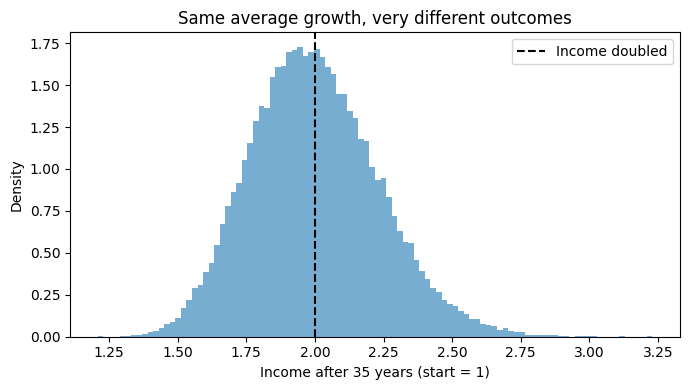

In [11]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.hist(income_factor, bins=100, density=True, alpha=0.6)
ax.axvline(2.0, color='black', linestyle='--', label='Income doubled')
ax.set_xlabel('Income after 35 years (start = 1)')
ax.set_ylabel('Density')
ax.set_title('Same average growth, very different outcomes')
ax.legend()
fig.tight_layout()
plt.show()

The rule of 70 describes the **typical** country: about half have doubled after 35 years, half have not. Countries with the same average growth end up far apart, only because of lucky and unlucky years. `np.mean(income_factor >= 2)` is a Monte Carlo **probability**: the average of a Boolean array is the share of `True` values.

> **Stop Video 8B.** You can estimate an expected value and a probability by Monte Carlo and know how the error shrinks with the number of draws.

<a id='video-8c'></a>
> **Start Video 8C**  
> Question: after a recession, does GDP return to its trend, or is the loss permanent?

## 4. <a id='toc4_'></a>[Is a recession permanent? Simulating over time](#toc0_)

Let $x_t$ be log GDP per capita as a **deviation from its trend**, in percent. Each year, part of last year's deviation survives and a new shock $\varepsilon_t$ hits:

$$x_t=\rho\,x_{t-1}+\varepsilon_t,\qquad \varepsilon_t\sim\mathcal{N}(0,\sigma^2).$$

This is an **AR(1) process** (autoregressive with one lag). The **persistence** $\rho$ answers our question:

- $\rho=0.9$: 90% of a deviation survives each year, so GDP **returns to trend**; a recession is temporary.
- $\rho=1$: the deviation never shrinks, so a recession is **permanent** (a random walk).

Economists have long debated which description fits real GDP better. We simply compare the two.

### 4.1 One recession, no other shocks

Start with a single recession of $-5$ percent in year 1 and no other shocks. The loop runs over **time**, because year $t$ needs year $t-1$.

**Pause and predict:** how far below trend is GDP after 10 years with $\rho=0.9$?

rho = 0.9: deviation after 10 years: -1.94 percent
rho = 1.0: deviation after 10 years: -5.00 percent


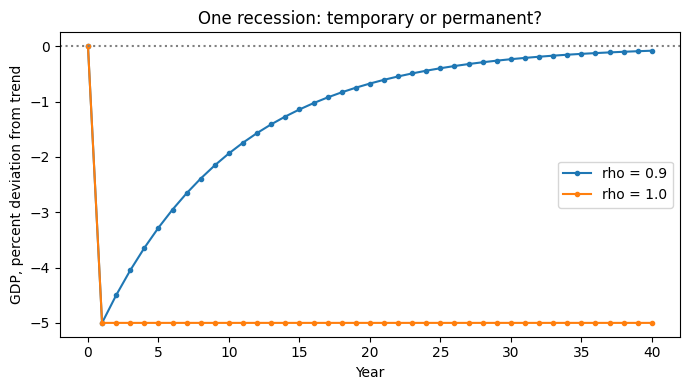

In [12]:
T = 40

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
for rho in [0.9, 1.0]:
    x = np.zeros(T + 1)
    shocks = np.zeros(T + 1)
    shocks[1] = -5.0                     # the recession
    for t in range(1, T + 1):
        x[t] = rho*x[t-1] + shocks[t]
    print(f'rho = {rho}: deviation after 10 years: {x[10]:.2f} percent')
    ax.plot(x, marker='.', label=f'rho = {rho}')

ax.axhline(0.0, color='grey', linestyle=':')
ax.set_xlabel('Year')
ax.set_ylabel('GDP, percent deviation from trend')
ax.set_title('One recession: temporary or permanent?')
ax.legend()
fig.tight_layout()
plt.show()

### 4.2 Shocks every year

Now a new random shock hits every year, with $\sigma=2$ percent. We draw all shocks first and use **the same shocks** for both values of $\rho$, so the only difference is persistence.

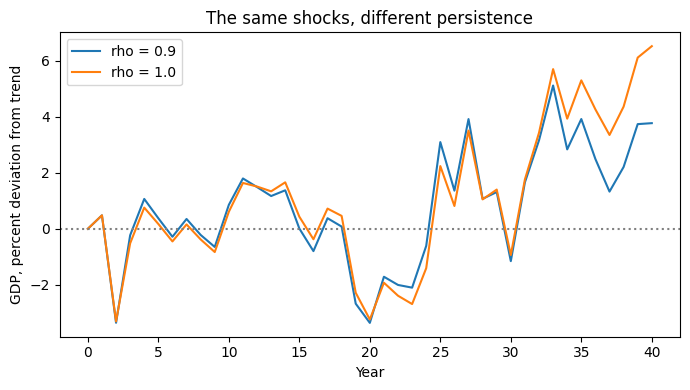

In [13]:
def simulate_gap(shocks, rho):
    """AR(1) path x_t = rho*x_{t-1} + shocks_t, starting at x_0 = 0."""
    x = np.zeros(shocks.size)
    for t in range(1, shocks.size):
        x[t] = rho*x[t-1] + shocks[t]
    return x


rng = np.random.default_rng(2026)
sigma = 2.0
shocks = rng.normal(0.0, sigma, size=T + 1)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
for rho in [0.9, 1.0]:
    ax.plot(simulate_gap(shocks, rho), label=f'rho = {rho}')
ax.axhline(0.0, color='grey', linestyle=':')
ax.set_xlabel('Year')
ax.set_ylabel('GDP, percent deviation from trend')
ax.set_title('The same shocks, different persistence')
ax.legend()
fig.tight_layout()
plt.show()

With $\rho=0.9$ GDP keeps crossing its trend. With $\rho=1$ it wanders away, because every shock stays forever. But this is **one** possible history. To compare the two worlds properly, we need many.

### 4.3 Many economies at once

We simulate **50,000 economies** for 40 years and look at the spread of $x_{40}$. The loop over time cannot be avoided, but the economies are **independent**, so one array operation updates all of them at once:

```python
x[:, t] = rho*x[:, t-1] + shocks[:, t]
```

Each **row** is one economy, each **column** one year.

rho = 0.9: std after 40 years =  4.58; share more than 10% below trend = 0.013
rho = 1.0: std after 40 years = 12.61; share more than 10% below trend = 0.214


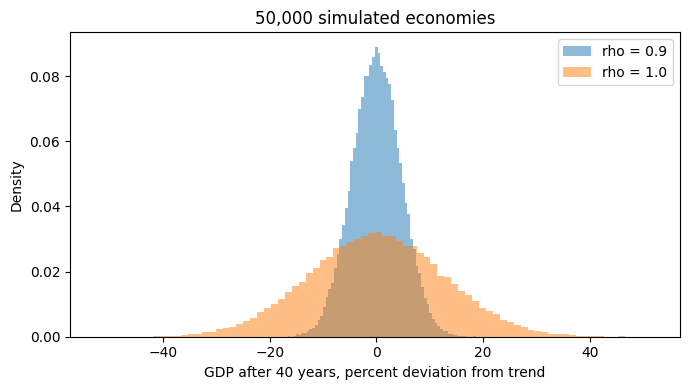

In [14]:
def simulate_gaps(rng, n_worlds, T, rho, sigma):
    """Simulate n_worlds independent AR(1) paths; returns an (n_worlds, T+1) array."""
    shocks = rng.normal(0.0, sigma, size=(n_worlds, T + 1))
    x = np.zeros((n_worlds, T + 1))
    for t in range(1, T + 1):
        x[:, t] = rho*x[:, t-1] + shocks[:, t]
    return x


n_worlds = 50_000
rng = np.random.default_rng(2026)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
for rho in [0.9, 1.0]:
    x_final = simulate_gaps(rng, n_worlds, T, rho, sigma)[:, -1]
    share_deep = np.mean(x_final < -10.0)
    print(f'rho = {rho}: std after {T} years = {np.std(x_final):5.2f}; '
          f'share more than 10% below trend = {share_deep:.3f}')
    ax.hist(x_final, bins=80, density=True, alpha=0.5, label=f'rho = {rho}')

ax.set_xlabel(f'GDP after {T} years, percent deviation from trend')
ax.set_ylabel('Density')
ax.set_title(f'{n_worlds:,} simulated economies')
ax.legend()
fig.tight_layout()
plt.show()

With permanent shocks, the spread keeps growing: after 40 years about one economy in five is more than 10% below its old trend. With $\rho=0.9$ that happens to only about one in 75.

**A known answer as a test.** For $\rho=1$, $x_{40}$ is the sum of 40 independent shocks, so its standard deviation is exactly $\sigma\sqrt{40}$:

In [15]:
print(f'Exact std for rho = 1: {sigma*np.sqrt(T):.2f}')

Exact std for rho = 1: 12.65


### 4.4 Why vectorize over economies?

The loop below does the same simulation one economy at a time. Both versions use the same seed, so they must give the same numbers. Compare the time.

In [16]:
import time


def simulate_gaps_loop(rng, n_worlds, T, rho, sigma):
    shocks = rng.normal(0.0, sigma, size=(n_worlds, T + 1))
    x = np.zeros((n_worlds, T + 1))
    for i in range(n_worlds):              # loop over economies (slow)
        for t in range(1, T + 1):
            x[i, t] = rho*x[i, t-1] + shocks[i, t]
    return x


t0 = time.time()
x_loop = simulate_gaps_loop(np.random.default_rng(0), n_worlds, T, 0.9, sigma)
time_loop = time.time() - t0

t0 = time.time()
x_vec = simulate_gaps(np.random.default_rng(0), n_worlds, T, 0.9, sigma)
time_vec = time.time() - t0

print('Same results:', np.allclose(x_loop, x_vec))
print(f'Loop over economies: {time_loop:.3f} seconds')
print(f'Vectorized:          {time_vec:.3f} seconds')

Same results: True
Loop over economies: 1.045 seconds
Vectorized:          0.063 seconds


**Rule of thumb:** loop over what is **sequential** (time); vectorize over what is **independent** (economies, households, draws). The Solow model in Lecture 11 uses the same loop over time.

## 5. <a id='toc5_'></a>[Summary](#toc0_)

| Tool | What it does | Remember |
| --- | --- | --- |
| `rng = np.random.default_rng(seed)` | a reproducible generator | same seed, same sequence; drawing again continues it |
| `rng.normal`, `rng.uniform`, `rng.integers` | draws from a distribution | `size=(rows, columns)` gives a whole array |
| Monte Carlo average | expected values and probabilities | error shrinks like $1/\sqrt{N}$; check with a known answer |
| AR(1) simulation | an economy hit by shocks over time | loop over time, vectorize over economies |

**Macro take-aways:** the same average growth rate can produce very different incomes, and whether recessions are temporary or permanent changes long-run risk dramatically.

> **Stop Video 8C.** End of Lecture 8's recording sequence.

## 6. <a id='toc6_'></a>[Optional: saving simulation results](#toc0_)

**Optional reading, not part of the videos or the class.** Large simulations can take a long time. `np.savez` stores several arrays in one file, and `np.load` reads them back. For other Python objects, such as dictionaries, the `pickle` module works in the same way ([pickle documentation](https://docs.python.org/3/library/pickle.html)).

In [17]:
# a. save two arrays in one file
np.savez('simulation_results.npz', x_final=x_final, income_factor=income_factor)

# b. load them again
with np.load('simulation_results.npz') as data:
    x_loaded = data['x_final']

print('Loaded the same numbers:', np.allclose(x_loaded, x_final))

Loaded the same numbers: True


### References

[NumPy random generator](https://numpy.org/doc/stable/reference/random/generator.html) and [scipy.stats.norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html).